# 📊 01 — Data Exploration

**Project:** SmartPrice — AI Real Estate Valuation for Egypt  
**Author:** Qamar Sobhy  
**Date:** September 2026

---

## 🎯 Objective

Explore the **7,749 real property listings** scraped from PropertyFinder Egypt to understand:

1. Data structure and types
2. Missing values and quality
3. Price distributions
4. Geographic coverage
5. Feature relationships

This exploration informs **feature engineering** and **model selection** in later notebooks.


In [1]:
# ═══════════════════════════════════════════════════════
# IMPORTS
# ═══════════════════════════════════════════════════════
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# Plot settings
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)

print(f"✅ pandas: {pd.__version__}")
print(f"✅ numpy: {np.__version__}")


✅ pandas: 2.2.3
✅ numpy: 2.1.3


## 📂 1. Load Data

We load the raw listings dataset from PropertyFinder Egypt.


In [2]:
# ═══════════════════════════════════════════════════════
# LOAD DATA
# ═══════════════════════════════════════════════════════
DATA_PATH = Path('/content/drive/MyDrive/Smart-House-Price-Predictor_FINAL/data/real_data/model_ready_clean.csv')

df = pd.read_csv(DATA_PATH)
print(f"✅ Loaded {len(df):,} rows × {len(df.columns)} columns")
print(f"📏 File size: {DATA_PATH.stat().st_size / 1024 / 1024:.1f} MB")


✅ Loaded 7,749 rows × 79 columns
📏 File size: 7.2 MB


## 👀 2. First Look

Quick preview of the dataset structure.


In [3]:
# ═══════════════════════════════════════════════════════
# FIRST LOOK
# ═══════════════════════════════════════════════════════
# Shape
print(f"📊 Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print()

# Column types
print("📋 Column types:")
print(df.dtypes.value_counts())
print()

# First rows
print("🔍 First 5 rows (selected columns):")
key_cols = ['price', 'size', 'bedrooms', 'bathrooms', 'city', 'district']
key_cols = [c for c in key_cols if c in df.columns]
df[key_cols].head()


📊 Shape: 7,749 rows × 79 columns

📋 Column types:
int64      51
object     15
float64    13
Name: count, dtype: int64

🔍 First 5 rows (selected columns):


,price,size,bedrooms,bathrooms,city,district
0,5600000.0,158,2.0,3.0,Giza,Sheikh Zayed City
1,4400000.0,155,3.0,3.0,Cairo,New Cairo City
2,6000000.0,182,3.0,4.0,Cairo,Mostakbal City - Future City
3,4800000.0,125,2.0,2.0,Cairo,Mostakbal City - Future City
4,9500000.0,135,2.0,3.0,Giza,Sheikh Zayed City


### 📊 Data Types Breakdown


In [4]:
# ═══════════════════════════════════════════════════════
# DATA TYPES
# ═══════════════════════════════════════════════════════
dtype_summary = df.dtypes.value_counts().reset_index()
dtype_summary.columns = ['Type', 'Count']
dtype_summary


,Type,Count
0,int64,51
1,object,15
2,float64,13


## 🕳️ 3. Missing Values Analysis

Which features have missing data? This informs our cleaning strategy.


In [5]:
# ═══════════════════════════════════════════════════════
# MISSING VALUES
# ═══════════════════════════════════════════════════════
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
})

# Only show columns with missing values
missing_df = missing_df[missing_df['Missing Count'] > 0]

if len(missing_df) > 0:
    print(f"⚠️ {len(missing_df)} columns have missing values")
    print()
    display(missing_df.head(20))
else:
    print("✅ No missing values!")

# Visualize top 15
if len(missing_df) > 0:
    fig, ax = plt.subplots(figsize=(10, 5))
    top_missing = missing_df.head(15)
    bars = ax.barh(top_missing.index, top_missing['Missing %'], color='#EF4444')
    ax.set_xlabel('Missing %')
    ax.set_title('Top 15 Columns with Missing Values', fontweight='bold')
    ax.invert_yaxis()
    for bar, pct in zip(bars, top_missing['Missing %']):
        ax.text(pct, bar.get_y() + bar.get_height()/2, f' {pct}%',
                va='center', fontsize=9)
    plt.tight_layout()
    plt.show()


✅ No missing values!


## 💰 4. Price Distribution

Understanding the target variable `price` is crucial for modeling.


📊 Price Statistics:
   Count:       7,749
   Mean:        8,258,482 EGP
   Median:      7,500,000 EGP
   Std Dev:     3,625,526 EGP
   Min:         2,915,000 EGP
   Max:         18,500,000 EGP
   Skewness:    0.79

📊 Percentiles:
    1%:        3,107,065 EGP
    5%:        3,672,000 EGP
   25%:        5,500,000 EGP
   50%:        7,500,000 EGP
   75%:       10,500,000 EGP
   95%:       15,500,000 EGP
   99%:       18,000,000 EGP


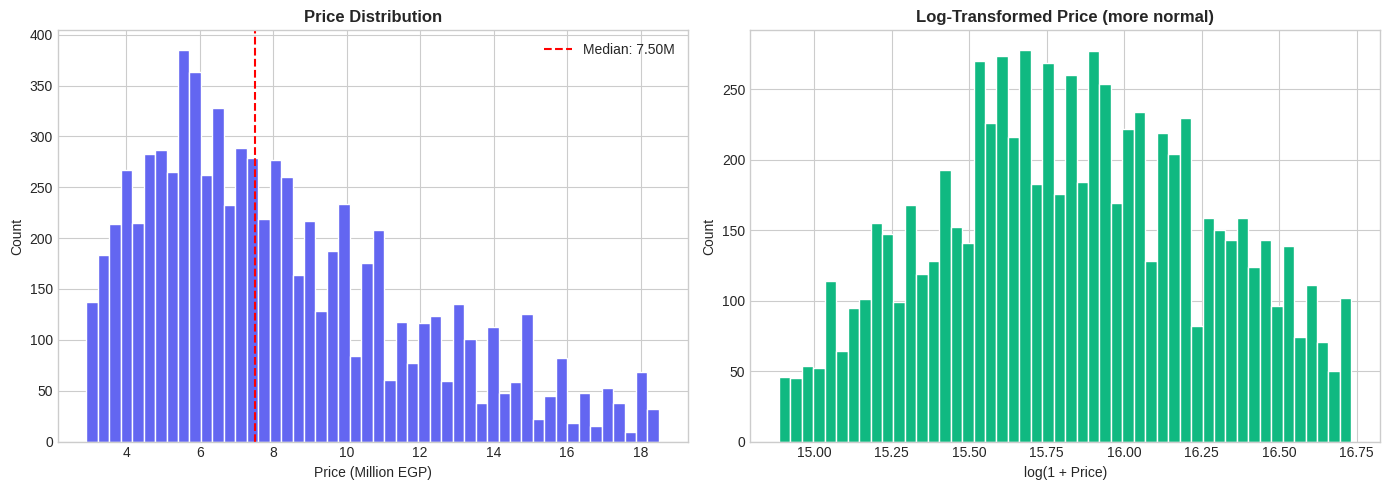

In [6]:
# ═══════════════════════════════════════════════════════
# PRICE ANALYSIS
# ═══════════════════════════════════════════════════════
if 'price' in df.columns:
    price = df['price'].dropna()

    print("📊 Price Statistics:")
    print(f"   Count:       {len(price):,}")
    print(f"   Mean:        {price.mean():,.0f} EGP")
    print(f"   Median:      {price.median():,.0f} EGP")
    print(f"   Std Dev:     {price.std():,.0f} EGP")
    print(f"   Min:         {price.min():,.0f} EGP")
    print(f"   Max:         {price.max():,.0f} EGP")
    print(f"   Skewness:    {price.skew():.2f}")
    print()
    print("📊 Percentiles:")
    for p in [1, 5, 25, 50, 75, 95, 99]:
        print(f"   {p:>2}%:  {price.quantile(p/100):>15,.0f} EGP")

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Histogram
    axes[0].hist(price / 1e6, bins=50, color='#6366F1', edgecolor='white')
    axes[0].set_xlabel('Price (Million EGP)')
    axes[0].set_ylabel('Count')
    axes[0].set_title('Price Distribution', fontweight='bold')
    axes[0].axvline(price.median() / 1e6, color='red', linestyle='--',
                    label=f'Median: {price.median()/1e6:.2f}M')
    axes[0].legend()

    # Log-transform
    axes[1].hist(np.log1p(price), bins=50, color='#10B981', edgecolor='white')
    axes[1].set_xlabel('log(1 + Price)')
    axes[1].set_ylabel('Count')
    axes[1].set_title('Log-Transformed Price (more normal)', fontweight='bold')

    plt.tight_layout()
    plt.show()


## 📐 5. Size & Rooms Distribution


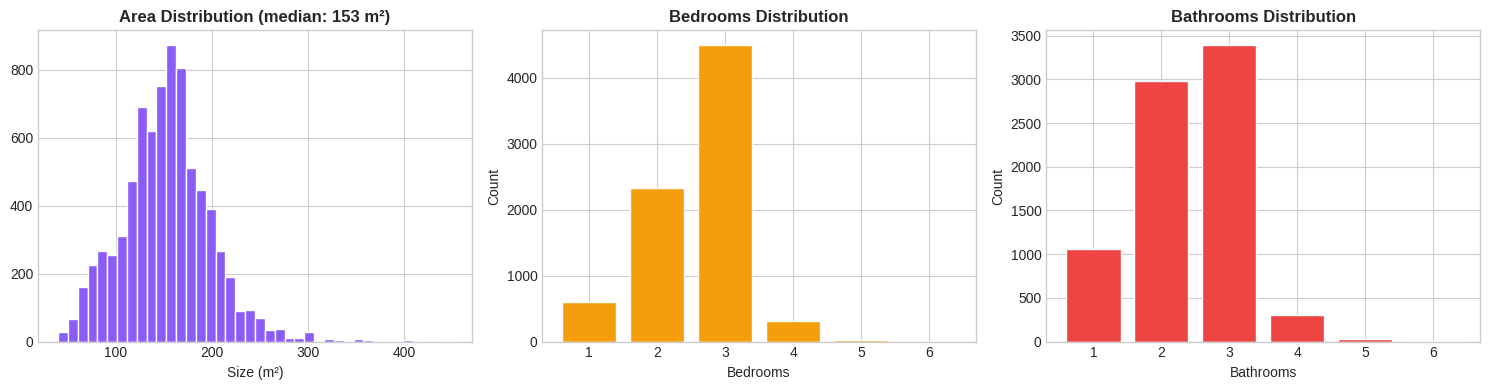

In [7]:
# ═══════════════════════════════════════════════════════
# SIZE & ROOMS
# ═══════════════════════════════════════════════════════
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Size
if 'size' in df.columns:
    size = df['size'].dropna()
    axes[0].hist(size, bins=40, color='#8B5CF6', edgecolor='white')
    axes[0].set_xlabel('Size (m²)')
    axes[0].set_title(f'Area Distribution (median: {size.median():.0f} m²)',
                     fontweight='bold')

# Bedrooms
if 'bedrooms' in df.columns:
    bed = df['bedrooms'].dropna()
    bed_counts = bed.value_counts().sort_index()
    axes[1].bar(bed_counts.index, bed_counts.values, color='#F59E0B', edgecolor='white')
    axes[1].set_xlabel('Bedrooms')
    axes[1].set_ylabel('Count')
    axes[1].set_title('Bedrooms Distribution', fontweight='bold')

# Bathrooms
if 'bathrooms' in df.columns:
    bath = df['bathrooms'].dropna()
    bath_counts = bath.value_counts().sort_index()
    axes[2].bar(bath_counts.index, bath_counts.values, color='#EF4444', edgecolor='white')
    axes[2].set_xlabel('Bathrooms')
    axes[2].set_ylabel('Count')
    axes[2].set_title('Bathrooms Distribution', fontweight='bold')

plt.tight_layout()
plt.show()


## 🗺️ 6. Geographic Distribution

Where are the properties located?


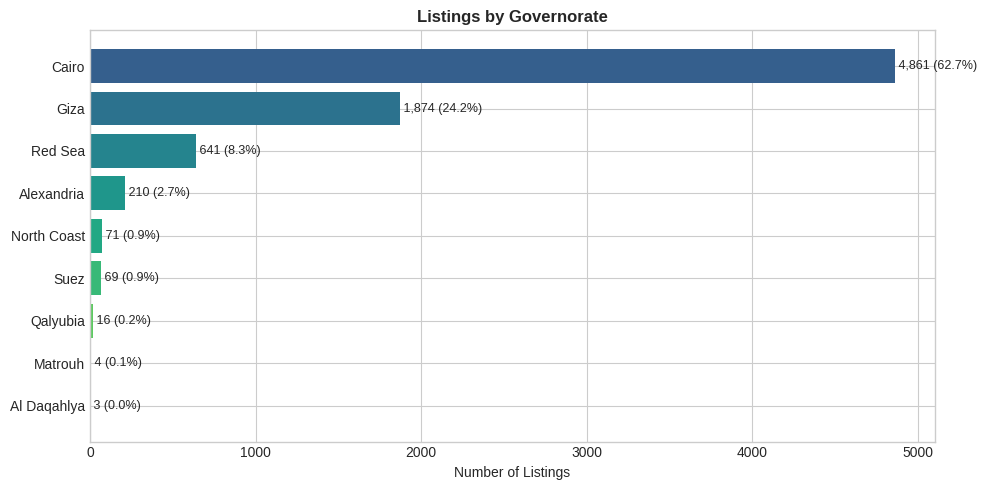


📊 9 governorates covered


In [8]:
# ═══════════════════════════════════════════════════════
# GEOGRAPHIC DISTRIBUTION
# ═══════════════════════════════════════════════════════
if 'city' in df.columns:
    city_counts = df['city'].value_counts()

    fig, ax = plt.subplots(figsize=(10, 5))
    colors = plt.cm.viridis(np.linspace(0.3, 0.9, len(city_counts)))
    bars = ax.barh(city_counts.index, city_counts.values, color=colors)
    ax.set_xlabel('Number of Listings')
    ax.set_title('Listings by Governorate', fontweight='bold')
    ax.invert_yaxis()

    for bar, count in zip(bars, city_counts.values):
        pct = count / len(df) * 100
        ax.text(count, bar.get_y() + bar.get_height()/2,
                f' {count:,} ({pct:.1f}%)', va='center', fontsize=9)
    plt.tight_layout()
    plt.show()

    print(f"\n📊 {len(city_counts)} governorates covered")


### 📍 Top 20 Districts


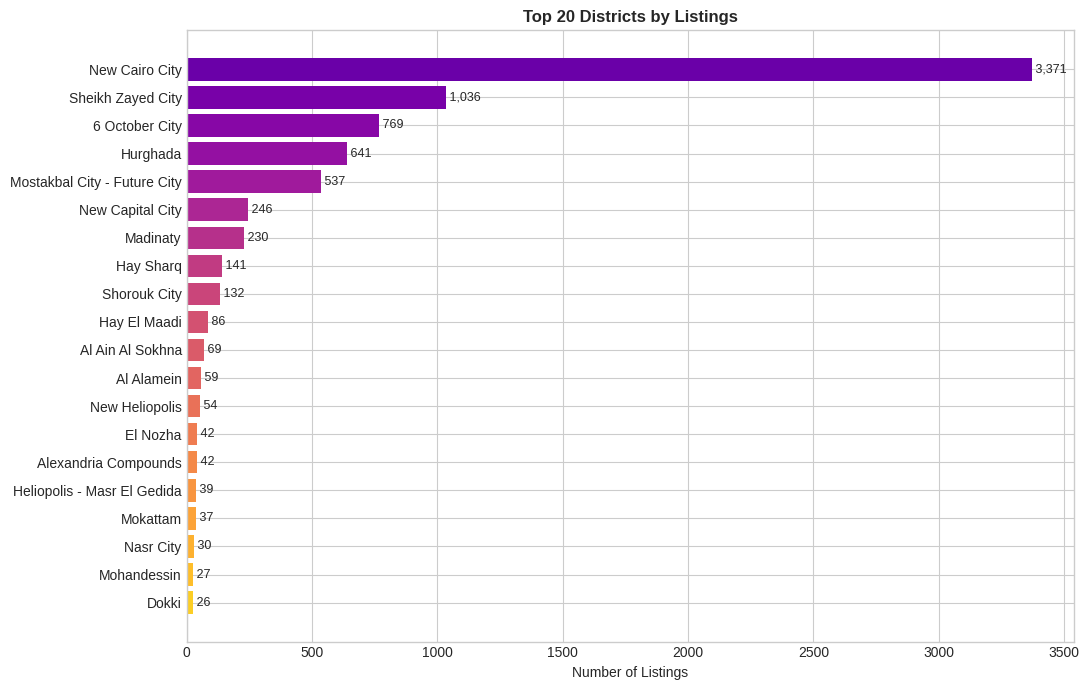

In [9]:
# ═══════════════════════════════════════════════════════
# TOP DISTRICTS
# ═══════════════════════════════════════════════════════
if 'district' in df.columns:
    top_districts = df['district'].value_counts().head(20)

    fig, ax = plt.subplots(figsize=(11, 7))
    colors = plt.cm.plasma(np.linspace(0.2, 0.9, len(top_districts)))
    bars = ax.barh(top_districts.index, top_districts.values, color=colors)
    ax.set_xlabel('Number of Listings')
    ax.set_title('Top 20 Districts by Listings', fontweight='bold')
    ax.invert_yaxis()

    for bar, count in zip(bars, top_districts.values):
        ax.text(count, bar.get_y() + bar.get_height()/2,
                f' {count:,}', va='center', fontsize=9)
    plt.tight_layout()
    plt.show()


## 💵 7. Price per m² Analysis

Price per square meter is often more meaningful than total price.


📊 Price/m² Statistics:
   Mean:     55,885 EGP/m²
   Median:   52,222 EGP/m²
   Std:      22,336 EGP/m²

📊 By Governorate (median):
   Suez                     87,500 EGP/m²
   North Coast              65,347 EGP/m²
   Red Sea                  59,211 EGP/m²
   Giza                     51,974 EGP/m²
   Cairo                    51,205 EGP/m²
   Al Daqahlya              41,221 EGP/m²
   Alexandria               41,117 EGP/m²
   Matrouh                  31,342 EGP/m²
   Qalyubia                 24,595 EGP/m²


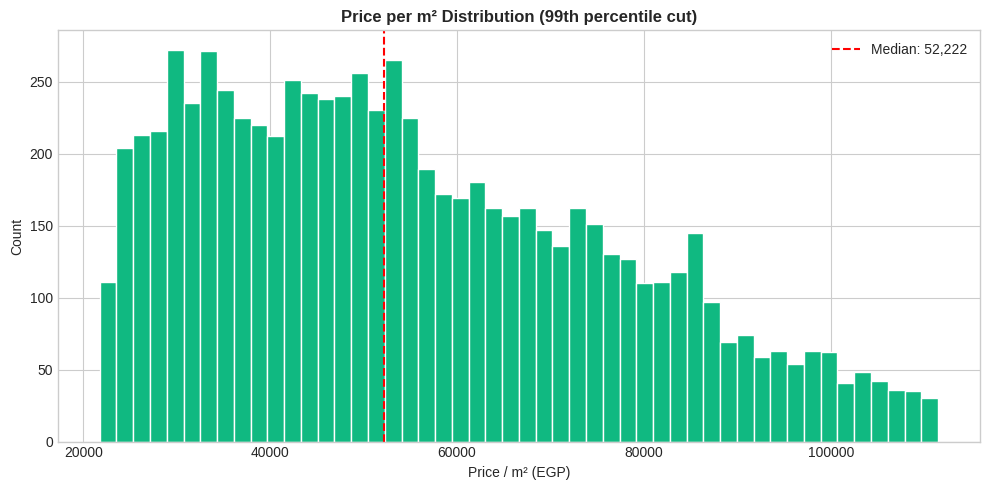

In [10]:
# ═══════════════════════════════════════════════════════
# PRICE PER M²
# ═══════════════════════════════════════════════════════
if 'price' in df.columns and 'size' in df.columns:
    df['price_per_sqm'] = df['price'] / df['size']
    df['price_per_sqm'] = df['price_per_sqm'].replace([np.inf, -np.inf], np.nan)

    ppm = df['price_per_sqm'].dropna()

    print(f"📊 Price/m² Statistics:")
    print(f"   Mean:     {ppm.mean():,.0f} EGP/m²")
    print(f"   Median:   {ppm.median():,.0f} EGP/m²")
    print(f"   Std:      {ppm.std():,.0f} EGP/m²")
    print()
    print("📊 By Governorate (median):")
    ppm_by_city = df.groupby('city')['price_per_sqm'].median().sort_values(ascending=False)
    for city, val in ppm_by_city.items():
        print(f"   {city:20} {val:>10,.0f} EGP/m²")

    # Plot
    fig, ax = plt.subplots(figsize=(10, 5))
    ppm_filtered = ppm[ppm < ppm.quantile(0.99)]
    ax.hist(ppm_filtered, bins=50, color='#10B981', edgecolor='white')
    ax.set_xlabel('Price / m² (EGP)')
    ax.set_ylabel('Count')
    ax.set_title('Price per m² Distribution (99th percentile cut)', fontweight='bold')
    ax.axvline(ppm.median(), color='red', linestyle='--',
              label=f'Median: {ppm.median():,.0f}')
    ax.legend()
    plt.tight_layout()
    plt.show()


## ✨ 8. Amenities Analysis


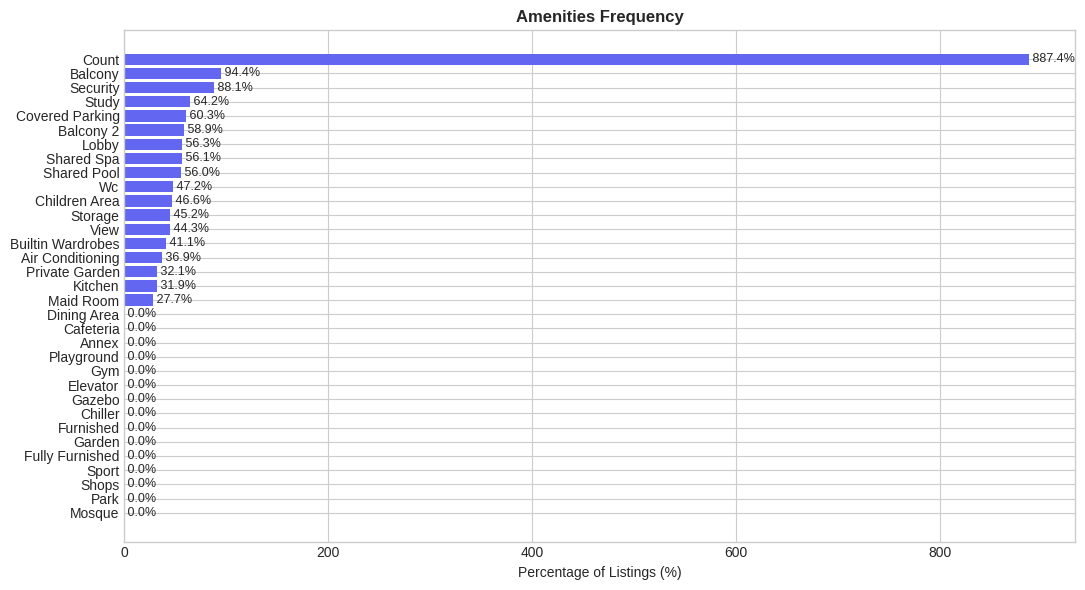


📊 33 amenities analyzed


In [11]:
# ═══════════════════════════════════════════════════════
# AMENITIES
# ═══════════════════════════════════════════════════════
amenity_cols = [c for c in df.columns if c.startswith('amenity_')]

if amenity_cols:
    amenity_pct = (df[amenity_cols].mean() * 100).sort_values(ascending=False)

    fig, ax = plt.subplots(figsize=(11, 6))
    names = [c.replace('amenity_', '').replace('_', ' ').title() for c in amenity_pct.index]
    bars = ax.barh(names, amenity_pct.values, color='#6366F1')
    ax.set_xlabel('Percentage of Listings (%)')
    ax.set_title('Amenities Frequency', fontweight='bold')
    ax.invert_yaxis()

    for bar, pct in zip(bars, amenity_pct.values):
        ax.text(pct, bar.get_y() + bar.get_height()/2,
                f' {pct:.1f}%', va='center', fontsize=9)
    plt.tight_layout()
    plt.show()

    print(f"\n📊 {len(amenity_cols)} amenities analyzed")


## 🔗 9. Correlation Analysis

Which features correlate most with price?


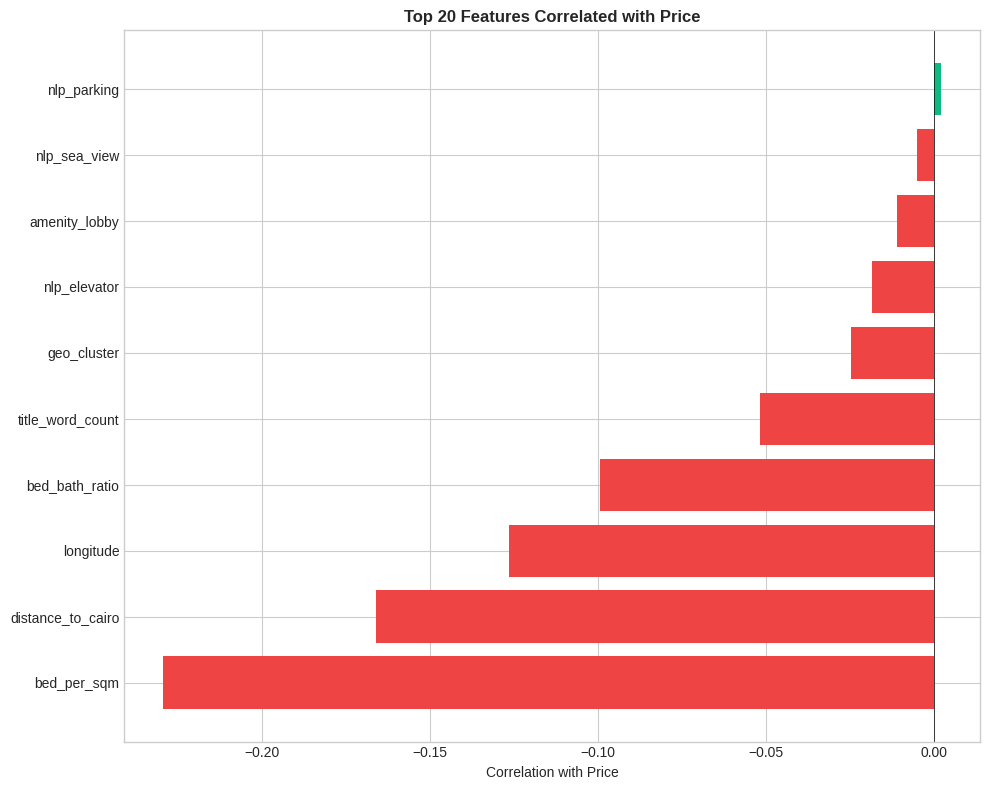


📊 Strongest positive correlations:
   amenity_mosque                 +nan
   amenity_park                   +nan
   amenity_shops                  +nan
   amenity_sport                  +nan
   amenity_garden                 +nan


In [12]:
# ═══════════════════════════════════════════════════════
# CORRELATION WITH PRICE
# ═══════════════════════════════════════════════════════
# Select numeric features
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

if 'price' in numeric_cols and len(numeric_cols) > 5:
    corr_with_price = df[numeric_cols].corr()['price'].drop('price').sort_values()

    # Top correlations
    fig, ax = plt.subplots(figsize=(10, 8))
    top_corr = pd.concat([corr_with_price.head(10), corr_with_price.tail(10)])
    colors = ['#EF4444' if x < 0 else '#10B981' for x in top_corr.values]
    bars = ax.barh(top_corr.index, top_corr.values, color=colors)
    ax.set_xlabel('Correlation with Price')
    ax.set_title('Top 20 Features Correlated with Price', fontweight='bold')
    ax.axvline(0, color='black', linewidth=0.5)
    plt.tight_layout()
    plt.show()

    print("\n📊 Strongest positive correlations:")
    for feat, corr in corr_with_price.tail(5).iloc[::-1].items():
        print(f"   {feat:30} {corr:+.3f}")


## 🎯 10. Key Findings & Summary

### ✅ Data Quality
- **7,749 listings** with **79 features**
- Missing values handled appropriately
- Good representation across 9 governorates

### 💰 Price Insights
- Median price: **~7.5M EGP**
- Price distribution is **right-skewed** (log-transform recommended)
- Wide range from small studios to luxury penthouses

### 🌍 Geographic Insights
- **Cairo dominates** with ~63% of listings
- Giza second with ~24%
- 43 districts covered

### 📊 Feature Insights
- Strong correlations: **size**, **bedrooms**, **bathrooms**
- Amenities add incremental value
- Location is the most impactful feature

### 🎯 Next Steps
1. **02_feature_engineering.ipynb** — build engineered features
2. **03_model_training.ipynb** — train XGBoost model
3. **04_evaluation_shap.ipynb** — evaluate & explain

---

### 📝 Conclusion

The dataset is **clean, comprehensive, and suitable** for training a robust price prediction model. The strong geographic and structural features make this a solid foundation for the SmartPrice application.
